# Does the MTM parallel extent depend on anything but k_y and ŝ? (Fusion_PhD-bhx7.8)

**Question.** The extent law `θ₉₅ = 9.46 kᵧ^−0.351 ŝ^−0.527 [π]` (`Fusion_PhD-9h5`, fitted to a 5×5 (kᵧ, ŝ) GS2 scan, `Fusion_PhD-497`) sizes GFTM's basis. It assumes the extent depends on **only** kᵧ and ŝ. The existing figures never plot the extent against any other parameter. This notebook does, on every existing GS2 database where a parameter varies; **no new runs**.

**Extent.** pyrokinetics `Extent` (95 % rule, full span in units of π) of `|φ|² + |A∥|²` at the final time of each GS2 run. This is the field and definition of the law's numbers (`MTM_analysis.mtm_detect_gs2scan.harvest_one`); it is checked below by reproducing the 5×5 numbers of `results/mtm_kxscan`.

**Data** (`GK_DATA_ROOT/GS2/Runs/`):
- `KX_SCAN/NSTX_MTM/ky_shat_5x5/grid`: 5×5 (kᵧ, ŝ) grid, everything else fixed. The law's fitting data.
- `KX_SCAN/NSTX_MTM/nu_beta_ladders/{nu,beta}/{base,shat_low,ky_high}`: one-axis ladders in ν (both species together) and β at three fixed (kᵧ, ŝ). The ×1 rung is the 5×5 grid cell itself.
- `LATIN_HYPERCUBE/NSTX_MTM/beta_q_shat_ky_n1000`: 1000-point Latin hypercube (β, q, ŝ, kᵧ vary).

**Parameters** are read from each run's own deck through pyrokinetics (`Pyro`), not assumed: kᵧ, ŝ, q, β, ν, the four gradients and the Miller shape. A parameter that does not vary in a database cannot be tested there; the notebook says which.

**MTM population.** n1000: `general_analysis.mode_classification` label `MTM` (consensus of tearing parity, mode direction and χₑ/χᵢ). 5×5 and ladders: *tearing parity* (A∥ even fraction E > 0.5, `FieldLine.compute_linear_parity`) and electron direction (ω < 0), the MTM definition of `mtm_core_tail`; the strict consensus label was tried first and keeps only 6 of 25 grid cells and no ladder rung, because it demands χₑ/χᵢ > 10 and T > 0.7 on top of parity. A sensitivity cell re-does n1000 with the same tearing-parity gate. All: growth rate > 0 and `frac_edge` < 1e-2 (the 497 box gate: the extent is not truncated by the θ box). Every drop is counted.

**Advisory.** The numbers are fits to these cases. "Depends" means the 95 % interval excludes zero; the effect size over the sampled range is always given beside it.

In [ ]:
import os, sys, warnings, json
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr, matplotlib.pyplot as plt
from scipy import stats
from matplotlib.ticker import StrMethodFormatter
from dotenv import load_dotenv
from pyrokinetics.diagnostics.extent import Extent
from pyrokinetics.pyroscan import PyroScanGKOutput

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file() and (p / "notebooks").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from general_analysis import mode_classification as mc

warnings.filterwarnings("ignore")
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
plt.rcParams.update({"axes.titlesize": 20, "axes.labelsize": 20, "xtick.labelsize": 17, "ytick.labelsize": 17, "legend.fontsize": 15})  # the user's format (kbm_extent_filter 10546f9)
def plain_ticks(ax):
    """Log axes: fixed 1-2-5 ticks inside the limits, plain {x:g} labels, no minor ticks (kbm_extent_filter format)."""
    for axis, lim, setter in ((ax.xaxis, ax.get_xlim(), ax.set_xticks), (ax.yaxis, ax.get_ylim(), ax.set_yticks)):
        if axis.get_scale() != "log": continue
        t = [m * 10.0 ** e for e in range(int(np.floor(np.log10(lim[0]))) - 1, int(np.ceil(np.log10(lim[1]))) + 1) for m in (1, 2, 5)]
        setter([v for v in t if lim[0] <= v <= lim[1]]); axis.set_major_formatter(StrMethodFormatter("{x:g}"))
        axis.set_minor_formatter(plt.NullFormatter()); axis.set_minor_locator(plt.NullLocator())
        (ax.set_xlim if axis is ax.xaxis else ax.set_ylim)(lim)
load_dotenv(ROOT / "local.env", override=True)
runs_root = Path(os.environ["GK_DATA_ROOT"]).expanduser() / "GS2" / "Runs"
plot_dir = ROOT / "Plots" / "mtm_extent_parameters"
plot_dir.mkdir(parents=True, exist_ok=True)
kx = runs_root / "KX_SCAN/NSTX_MTM"
lhc = runs_root / "LATIN_HYPERCUBE/NSTX_MTM/beta_q_shat_ky_n1000"
cells = ["base", "shat_low", "ky_high"]
# database -> cube directory (pyroscan.json + cube.nc of the tail-averaged GS2 runs)
sets = {"5x5": kx / "ky_shat_5x5/grid/pyro_cube_avg", "n1000": lhc / "pyro_cube_avg"}
for ladder in ("nu", "beta"):
    for c in cells:
        sets[f"{ladder}:{c}"] = kx / "nu_beta_ladders" / ladder / c / "pyro_cube_avg"
law_published = dict(a=-0.351, b=-0.527, envelope=9.46, margin=1.327)  # results/mtm_kxscan_widefit, Fusion_PhD-9h5
gate_edge, gate_gamma = 1e-2, 0.0
print({k: v.exists() for k, v in sets.items()})

## Load

One cube per database (`pyro_cube_avg`: tail-averaged GS2 runs with complex fields and fluxes), loaded with its `pyroscan.json`; no run directory is read (Fusion_PhD-use8). Per sample: the extent and edge weight from the cube, the mode-classification label from `mc.indicators(scan, ds)`, the parity E from the same call, and every parameter from the sample's Pyro, rebuilt in memory by `scan.sample_pyro` from the base input plus that sample's scanned values. kᵧ is converted to pyrokinetics units (ρ_ref,pyro), the unit of the law. Growth rate, frequency and fields are tail averages; the earlier version used each run's final time.

In [ ]:
plain = lambda a: a.pint.dequantify() if hasattr(a, "pint") else a
last = lambda a: plain(a).isel(time=-1) if "time" in a.dims else plain(a)
num = lambda v: float(getattr(v, "m", v))

def per_database(db, path):
    scan, ds = mc.load_gs2_cube(lhc, "pyro_cube_avg") if db == "n1000" else mc.load_gridded_cube(path)
    ds = mc.as_samples(scan, ds)
    ind = mc.indicators(scan, ds).to_dataframe()
    power = (abs(plain(ds["phi"])) ** 2 + abs(plain(ds["apar"])) ** 2).isel(kx=0, ky=0, missing_dims="ignore").squeeze()
    w = PyroScanGKOutput(xr.Dataset({"eigenfunctions_squared": power}))
    Extent(w)
    th, pw = np.asarray(power.theta), np.asarray(power)
    edge = np.trapezoid(pw * (abs(th) > 0.9 * abs(th).max()), th, axis=-1) / np.trapezoid(pw, th, axis=-1)
    rows = []
    for i, name in enumerate(ds.sample_name.values):
        p = scan.sample_pyro(i)
        ls, g = p.local_species, p.local_geometry
        e, ion = ls["electron"], ls[[s for s in ls.names if s != "electron"][0]]
        rows.append(dict(db=db, run=str(name), extent=float(plain(w["extent"]).values[i]) / np.pi, edge=float(edge[i]),
                         gamma=float(last(ds["growth_rate"]).squeeze().values[i]),
                         ky=num(p.numerics.ky.to(p.norms.pyrokinetics.rhoref ** -1)), shat=num(g.shat), q=num(g.q),
                         beta=num(p.numerics.beta), nu_e=num(e.nu), nu_i=num(ion.nu), aLTe=num(e.inverse_lt), aLTi=num(ion.inverse_lt),
                         aLne=num(e.inverse_ln), aLni=num(ion.inverse_ln), kappa=num(g.kappa), delta=num(g.delta),
                         s_kappa=num(g.s_kappa), s_delta=num(g.s_delta), shift=num(g.shift), beta_prime=num(g.beta_prime),
                         nperiod=float(p.numerics.nperiod)))
    return pd.DataFrame(rows).join(ind[["T", "E", "omega", "chi_ratio"]].reset_index(drop=True))

raw = pd.concat([per_database(db, path) for db, path in sets.items()], ignore_index=True)
failed = raw.iloc[:0]
df = raw.copy()
df["label"] = mc.classify(df)
df["tear"] = (df.E > 0.5) & (df.omega < 0)   # tearing parity, electron direction
print("loaded", df.groupby("db").size().to_dict())

## Population and counts

Each drop is counted, in order: load failure, not labelled `MTM`, growth rate ≤ 0, box contact. The ladders' ×1 rung is the 5×5 grid cell at the same (kᵧ, ŝ); it is added to each ladder group.

In [ ]:
is_mtm = np.where(df.db == "n1000", df.label == "MTM", df.tear)   # n1000: mode_classification label; KX_SCAN: parity + direction
unstable = df.gamma > gate_gamma
cut = is_mtm & unstable & (df.edge < gate_edge)
rows = []
for db, g in df.groupby("db", sort=False):
    rows.append(dict(db=db, n_dirs=len(g), loaded=len(g), **{f"label_{k}": v for k, v in g.label.value_counts().items()},
                     tearing_parity_omega_neg=int(g.tear.sum()), MTM_gate_and_unstable=int((is_mtm & unstable)[g.index].sum()), kept=int(cut[g.index].sum())))
counts = pd.DataFrame(rows).fillna(0).astype(int, errors="ignore")
print(counts.to_string(index=False))
good = df[cut]
groups = {"5x5": good[good.db == "5x5"], "n1000": good[good.db == "n1000"]}
for ladder in ("nu", "beta"):
    for c in cells:
        lad = good[good.db == f"{ladder}:{c}"]
        ref = good[(good.db == "5x5") & np.isclose(good.ky, lad.ky.iloc[0], rtol=1e-4) & np.isclose(good.shat, lad.shat.iloc[0], rtol=1e-4)] if len(lad) else lad
        groups[f"{ladder}:{c}"] = pd.concat([lad, ref])  # ×1 rung = the grid cell

## Which parameters vary where

Relative spread (max − min) / |mean| of each deck parameter in each group. Zero means the parameter is constant there and nothing can be said about it from that database.

In [4]:
names = ["ky", "shat", "q", "beta", "nu_e", "nu_i", "aLTe", "aLTi", "aLne", "aLni", "kappa", "delta", "s_kappa", "s_delta", "shift", "beta_prime", "nperiod"]
spread = pd.DataFrame({k: {n: np.ptp(g[n]) / abs(g[n].mean()) if len(g) else np.nan for n in names} for k, g in groups.items()})
print(spread.round(4).to_string())
varies = lambda g, n: len(g) > 2 and np.ptp(g[n]) > 1e-6 * abs(g[n].mean())
# the ladders move nu_i with nu_e by construction; nu_e stands for both
params = [n for n in names if any(varies(g, n) for g in groups.values()) and n != "nu_i"]
print("tested parameters:", params)
print("constant everywhere (untestable here):", [n for n in names if n not in params and n != "nu_i"])

               5x5   n1000  nu:base  nu:shat_low  nu:ky_high  beta:base  beta:shat_low  beta:ky_high
ky          1.5584  4.0338   0.0000       0.0000      0.0000     0.0000         0.0000        0.0000
shat        1.5309  1.6677   0.0000       0.0000      0.0000     0.0000         0.0000        0.0000
q           0.0000  1.3036   0.0000       0.0000      0.0000     0.0000         0.0000        0.0000
beta        0.0000  1.7189   0.0000       0.0000      0.0000     2.4194         2.4194        1.8667
nu_e        0.0000  0.0000   2.4194       2.4194      4.4912     0.0000         0.0000        0.0000
nu_i        0.0000  0.0000   2.4194       2.4194      4.4912     0.0000         0.0000        0.0000
aLTe        0.0000  0.0000   0.0000       0.0000      0.0000     0.0000         0.0000        0.0000
aLTi        0.0000  0.0000   0.0000       0.0000      0.0000     0.0000         0.0000        0.0000
aLne        0.0000  0.0000   0.0000       0.0000      0.0000     0.0000         0.0000     

## Fit helpers and the 5×5 check

`ols` is a plain least-squares fit with an intercept; the interval is `t₀.₉₇₅(n−k)·se`. A parameter is fitted in log if it is positive everywhere in the group, linearly otherwise (`ln extent` against the value, slope per unit). The first output reproduces the law's numbers on the 5×5 cube from these runs: the base cell, the two widest cells of the nperiod ladder, and the fit.

In [5]:
def ols(y, X):
    A = np.column_stack([np.ones(len(y)), np.atleast_2d(X.T).T if X.ndim == 1 else X]); n, k = A.shape
    b = np.linalg.lstsq(A, y, rcond=None)[0]; r = y - A @ b; rss = float(r @ r)
    se = np.sqrt(np.diag(rss / (n - k) * np.linalg.inv(A.T @ A)))
    return dict(b=b, ci=stats.t.ppf(0.975, n - k) * se, r2=1 - rss / float(((y - y.mean()) ** 2).sum()),
                aic=n * np.log(rss / n) + 2 * k, n=n)

is_log = lambda n: all((g[n] > 0).all() for g in groups.values() if len(g))
tx = lambda n, v: np.log(v) if is_log(n) else np.asarray(v, float)
pm = lambda f: f"{f['b'][-1]:+.3f}±{f['ci'][-1]:.3f}"
y_of = lambda g: np.log(g.extent.values)

g5 = groups["5x5"]
law = ols(y_of(g5), np.column_stack([tx("ky", g5.ky), tx("shat", g5.shat)]))
print(f"5x5 refit (n={law['n']}): a = {law['b'][1]:+.3f}±{law['ci'][1]:.3f}, b = {law['b'][2]:+.3f}±{law['ci'][2]:.3f}, "
      f"prefactor {np.exp(law['b'][0]):.2f}, R2 {law['r2']:.3f} | published a={law_published['a']}, b={law_published['b']}, centre prefactor {law_published['envelope'] / law_published['margin']:.2f}")
base = g5[np.isclose(g5.ky, 0.58085, atol=1e-4) & np.isclose(g5.shat, 1.32921, atol=1e-4)]
print("base cell extent [pi]:", base.extent.round(4).tolist(), "| 497 README: 6.289; widest cells 17.244 and 12.923:",
      g5.sort_values("extent", ascending=False).extent.head(2).round(3).tolist(), "(box-gated cells dropped here are not in these groups)")
a_law, b_law = law["b"][1], law["b"][2]

5x5 refit (n=24): a = -0.351±0.104, b = -0.527±0.103, prefactor 7.13, R2 0.886 | published a=-0.351, b=-0.527, centre prefactor 7.13
base cell extent [pi]: [6.2887] | 497 README: 6.289; widest cells 17.244 and 12.923: [17.244, 13.581] (box-gated cells dropped here are not in these groups)


## Figure 3. Multi-parameter regression

`ln extent` on the tested parameters (log, or linear where a parameter is not positive), per database. **n1000**: every parameter that varies there. **KX_SCAN pooled**: the 5×5 grid plus all ladder rungs, which is the only place ν varies (with kᵧ, ŝ, β). Collinear columns (|r| > 0.999, e.g. β′ ∝ β in the LHC deck) are dropped and named. `ΔR²` and `ΔAIC` are drop-one: R² lost and AIC *gained* (positive = the parameter helps) when that parameter alone is removed.

n1000 LHC n=497
 parameter  exponent   ci95    dR2     dAIC
        ky   -0.2883 0.0224 0.2565 412.1019
      shat   -0.5359 0.0310 0.4626 598.2650
         q   -0.4003 0.0478 0.1086 216.0322
      beta   -0.0224 0.1028 0.0001  -1.8141
beta_prime   -0.1167 0.2137 0.0005  -0.8359 
R2 = 0.8028

KX_SCAN pooled (5x5 + ladders) n=51
parameter  exponent   ci95    dR2    dAIC
       ky   -0.3168 0.1012 0.2287 29.7462
     shat   -0.4521 0.1065 0.4207 46.5024
     beta    0.0161 0.1061 0.0005 -1.8967
     nu_e   -0.1117 0.0516 0.1092 15.6035 
R2 = 0.7352



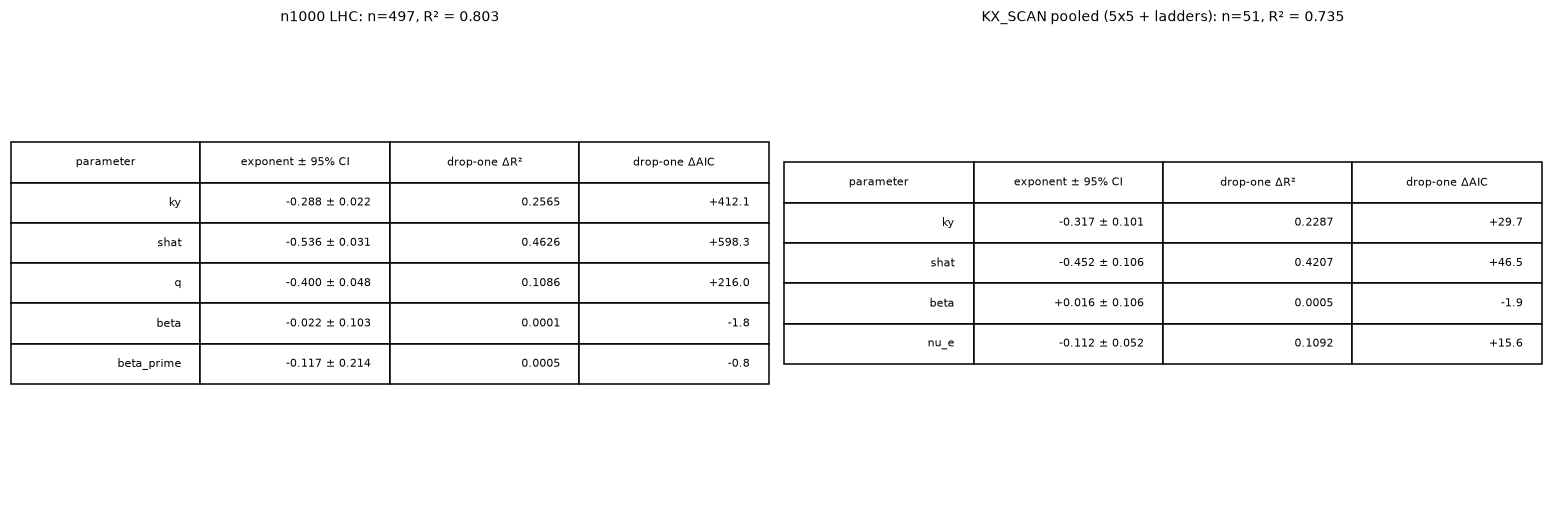

In [8]:
def regress(g, cand):
    cols = []
    for n in cand:
        if not varies(g, n): continue
        x = tx(n, g[n].values)
        if any(abs(np.corrcoef(x, c)[0, 1]) > 0.999 for _, c in cols):
            print(f"  dropped collinear: {n}"); continue
        cols.append((n, x))
    ns = [n for n, _ in cols]; y = y_of(g)
    full = ols(y, np.column_stack([c for _, c in cols]))
    out = []
    for j, n in enumerate(ns):
        sub = ols(y, np.column_stack([c for m, (_, c) in enumerate(cols) if m != j]))
        out.append(dict(parameter=n, exponent=full["b"][j + 1], ci95=full["ci"][j + 1], dR2=full["r2"] - sub["r2"], dAIC=sub["aic"] - full["aic"]))
    return pd.DataFrame(out), full

pooled = pd.concat([good[good.db == "5x5"], good[good.db.str.contains(":")]])
tables = {}
for title, g in (("n1000 LHC", groups["n1000"]), ("KX_SCAN pooled (5x5 + ladders)", pooled)):
    print(title, f"n={len(g)}")
    tables[title], full = regress(g, params)
    tables[title].attrs.update(r2=full["r2"], n=full["n"])
    print(tables[title].round(4).to_string(index=False), f"\nR2 = {full['r2']:.4f}\n")
fig, axs = plt.subplots(1, 2, figsize=(14, 0.5 * max(len(t) for t in tables.values()) + 2))
for ax, (title, t) in zip(axs, tables.items()):
    ax.axis("off"); ax.set_title(f"{title}: n={t.attrs['n']}, R² = {t.attrs['r2']:.3f}", fontsize=9)
    cell = [[r.parameter, f"{r.exponent:+.3f} ± {r.ci95:.3f}", f"{r.dR2:.4f}", f"{r.dAIC:+.1f}"] for r in t.itertuples()]
    ax.table(cellText=cell, colLabels=["parameter", "exponent ± 95% CI", "drop-one ΔR²", "drop-one ΔAIC"], loc="center").scale(1, 1.8)
fig.savefig(plot_dir / "gs2_mtm_extent_regression_coefficient_table.png")